# Step 1a — Otsu binarization

Result: `run_otsu` from `src/thresholding.py` (grayscale, longer side ≤ 1200 px → 5×5 blur → Otsu). The histogram panel shows where Otsu puts t*.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt

from src.thresholding import run_otsu, load_gray, preprocess, otsu_threshold

In [2]:
# Test images: synthetic clean / uneven light + own photos
def synthetic(h=200, w=700, seed=0):
    img = np.full((h, w), 225, np.uint8)
    P = lambda *xy: np.array(xy, np.int32).reshape(-1, 1, 2)
    for pts in [P(40,60, 70,40, 80,150), P(130,100, 200,100), P(165,65, 165,135), P(340,85, 410,85),
                P(340,115, 410,115), P(450,60, 500,45, 520,80, 450,150, 530,150), P(570,50, 640,150), P(640,50, 570,150)]:
        cv2.polylines(img, [pts], False, 40, 4)                      # 1 + = 2 x
    cv2.ellipse(img, (270, 100), (35, 50), 0, 0, 360, 40, 4)          # 0
    return np.clip(img + np.random.default_rng(seed).normal(0, 8, img.shape), 0, 255).astype(np.uint8)

clean = synthetic()
uneven = np.clip(clean * np.linspace(1.0, 0.25, clean.shape[1]), 0, 255).astype(np.uint8)
inputs = {"synthetic clean": clean, "synthetic uneven light": uneven}
photo_dir = ROOT / "data" / "raw" / "photos"
inputs |= {p.stem: p for p in sorted(photo_dir.glob("*")) if p.suffix.lower() in {".jpg", ".jpeg", ".png"}}
list(inputs)

['synthetic clean',
 'synthetic uneven light',
 'PHOTO-2026-11-20-23-54-12',
 'PHOTO-2026-11-21-01-41-35']

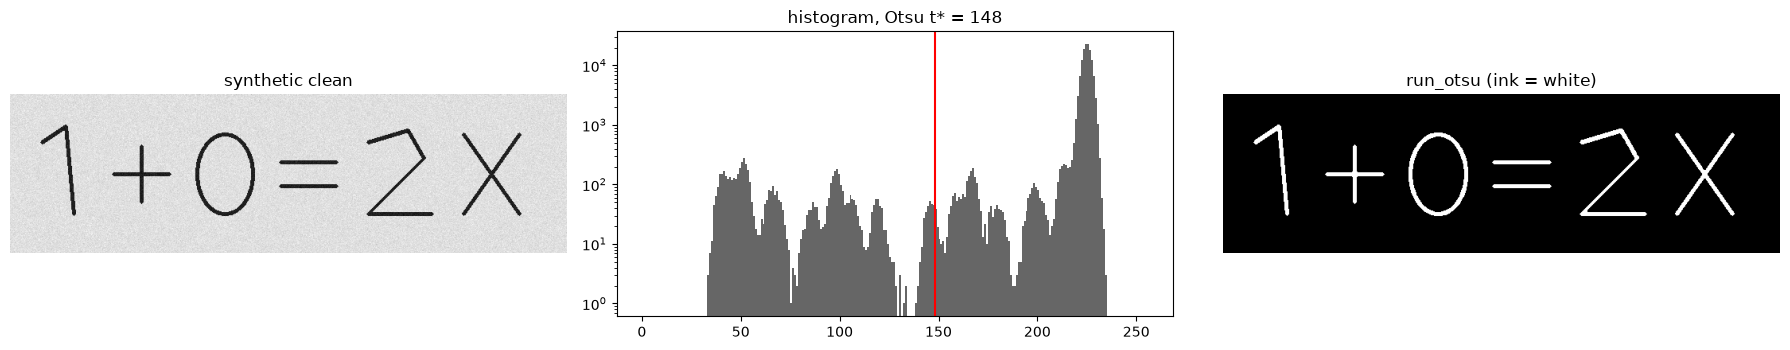

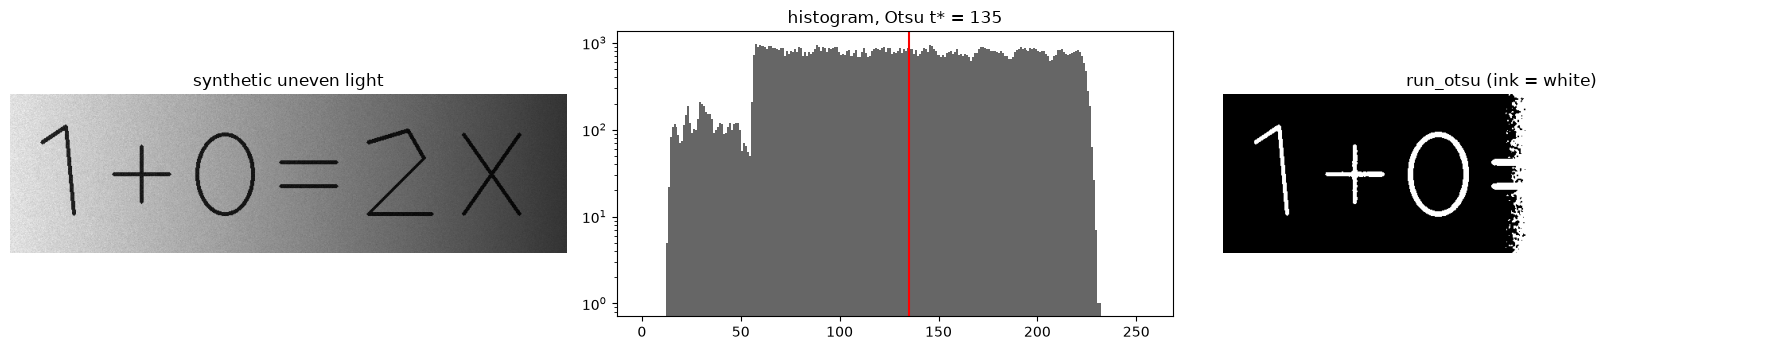

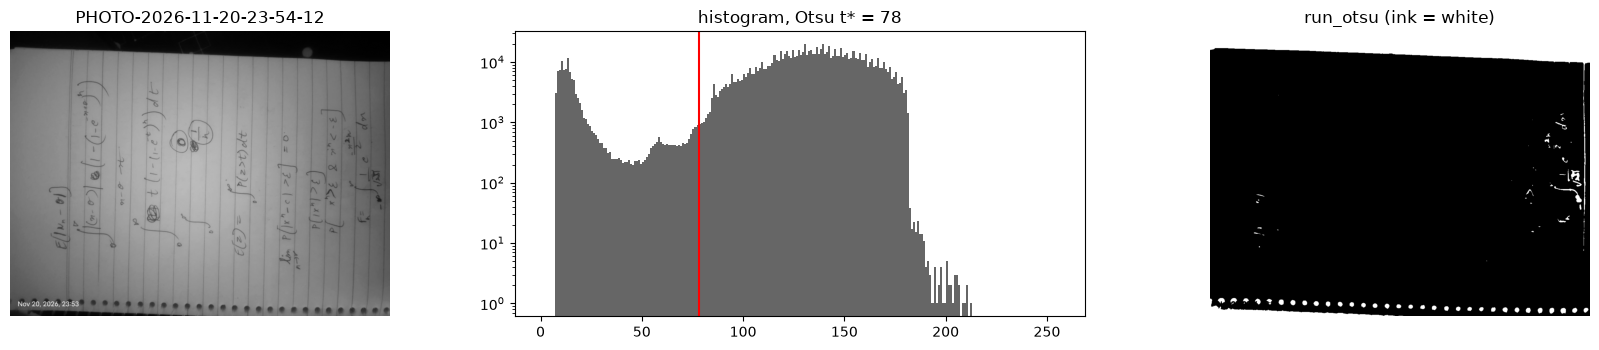

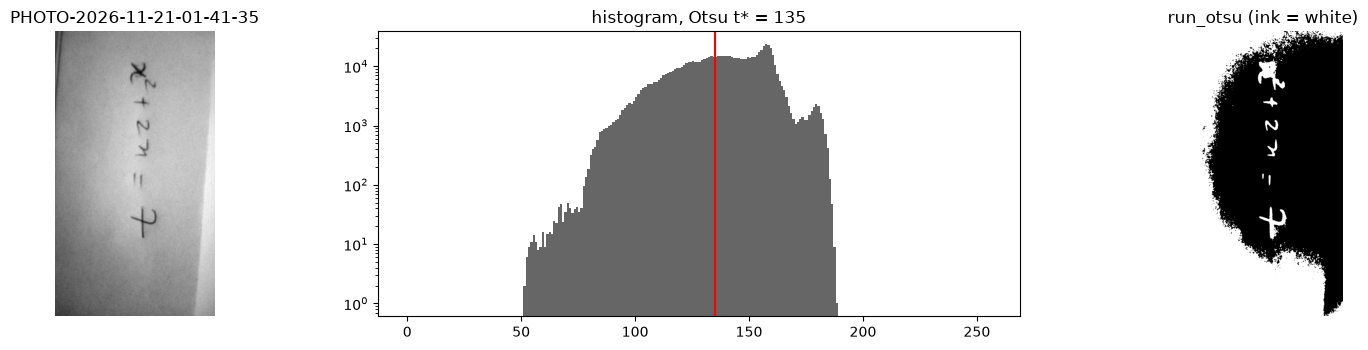

In [3]:
for name, src in inputs.items():
    gray = load_gray(src)
    t, _ = otsu_threshold(preprocess(gray))
    fig, ax = plt.subplots(1, 3, figsize=(18, 3.6))
    ax[0].imshow(gray, cmap="gray"); ax[0].set_title(name)
    ax[1].hist(preprocess(gray).ravel(), bins=256, range=(0, 256), color="0.4", log=True)
    ax[1].axvline(t, color="r"); ax[1].set_title(f"histogram, Otsu t* = {t}")
    ax[2].imshow(run_otsu(src), cmap="gray"); ax[2].set_title("run_otsu (ink = white)")
    ax[0].axis("off"); ax[2].axis("off"); plt.tight_layout(); plt.show()

**Observations**
- Clean image: bimodal histogram, clean strokes.
- Uneven light: no single t* separates ink from paper; the dark right side becomes ink.
- Photos: t* is set by the dark background / shadow, not by the ink, so the writing is lost. → motivates adaptive thresholding (notebook 02).